# Notebook 1 of 5: Random deposition, the simplest film-growth simulation

**Goal of this notebook:** understand, line by line, how the project simulates atoms raining onto a surface, how it
measures how *rough* the resulting film is, and how it proves that the code is correct by comparing with an exact
pen-and-paper answer.

## How to use this notebook

| | |
|---|---|
| **Prerequisites** | Basic Python (lists, loops, functions) and a first look at NumPy arrays. No physics needed: every term is explained when it first appears. |
| **Kernel** | *Thin Film Growth* (`thin-film-growth`, the project's `.venv`). Any Python 3.11+ with `requirements.txt` installed also works. |
| **Run order** | Run cells top to bottom (Kernel → Restart & Run All is safest). This is notebook 1 of 5: `01_random_deposition` → `02_surface_relaxation` → `03_temperature_model` → `04_trench_filling` → `05_por_yield_and_app`. Each one runs on its own, but the ideas build on each other. |
| **Runtime** | A few seconds on a laptop. |
| **Files written** | **None.** The notebook only *reads* `results/`. Scripts in `scripts/` are what write `results/` (Part 10). |

Keep `src/thin_film/random_deposition.py` and `src/thin_film/roughness.py` open next to this notebook. They are short
(about 100 and 80 lines) and every function used here comes from them.

## Table of contents
1. Setup and module map
2. The physical idea in plain words
3. Random numbers, Monte Carlo and seeds
4. The algorithm by hand: 10 columns, 5 monolayers
5. Measuring roughness W
6. Scaling up: one real film, then an ensemble
7. Power laws and log-log plots from scratch: the growth exponent beta
8. Checking against the exact theory
9. Small experiments: what changes and what doesn't
10. How `results/phase1_random_deposition/` is produced
11. Recap and exercises

## 1. Setup and module map

The first cell makes the project's `src/` folder importable, whether you start Jupyter from the project root or from
`notebooks/`. It also works in Google Colab (it fetches the project first). `RESULTS` is the path of the saved results
folder, which we only read.

In [1]:
# Setup: works locally (run from notebooks/ or the project root) and in Google Colab.
# In Colab the project code must be available: it is cloned from GitHub if that repo exists,
# otherwise copy the project folder to Google Drive as MyDrive/thin_film_growth.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/thin_film"):
    repo = "https://github.com/nhamhung/thin-film-growth.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/thin_film_growth"]).returncode == 0:
        os.chdir("/content/thin_film_growth")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/thin_film_growth")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
RESULTS = os.path.join(ROOT, "results")   # we only READ from here, never write
print("project root:", ROOT)

project root: <project-root>


Now the imports. Each import corresponds to one file in `src/thin_film/`:

| Module (file) | What we use from it | Role |
|---|---|---|
| `random_deposition.py` | `RDSettings`, `deposit_one`, `deposit`, `simulate`, `run_ensemble`, `theory_roughness` | the Phase 1 model |
| `roughness.py` | `roughness`, `fit_growth_exponent`, `measurement_times`, `ensemble_roughness` | measurements shared by all 1D models |
| `plotting.py` | `plot_surface`, `plot_roughness_loglog` | shared plots |

Other files (`results.py`, `scripts/run_phase1.py`, `tests/test_random_deposition.py`) are described later.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thin_film import random_deposition as rd
from thin_film.roughness import roughness, fit_growth_exponent, measurement_times
from thin_film.plotting import plot_surface, plot_roughness_loglog

np.set_printoptions(linewidth=120)

## 2. The physical idea in plain words

Computer chips are made by stacking **thin films**: coatings only a few to a few hundred atoms thick. A film is grown
by **deposition**: atoms are sent toward a flat disc (the **wafer**, or **substrate**) and settle on it, a bit like
snow falling on a table.

The project models the surface seen from the side as a row of `N` **columns**. A film is then nothing more than a
list of numbers: `heights[i]` = how many atoms are stacked in column `i`. Think of a row of coin stacks.

**The rule of random deposition** (the simplest possible model):

1. pick one column completely at random;
2. put the atom on top of that column (add 1 to its height);
3. repeat. The atom never moves again and ignores its neighbours.

Everyday analogy: rain drops falling into a row of identical glasses. Each drop lands in a random glass. Some glasses
end up fuller than others purely by chance.

Real atoms do slide around after landing (notebooks 2 to 4 add that). This model is still useful because it has an
**exact mathematical answer**, so it lets us test the simulation and measurement code before adding real physics.

**Time** is counted in **monolayers (ML)**. 1 ML = `N` atoms = on average one complete layer over the whole surface.
With 200 columns, 1000 ML means 200,000 atoms.

## 3. Random numbers, Monte Carlo and seeds

A **Monte Carlo** simulation (named after the casino) is a program that plays out a random process using random
numbers, like rolling dice. To get *reproducible* results, the dice are generated from a starting number, the
**seed**. The same seed always gives the same sequence of "random" numbers.

NumPy's modern random-number generator is `np.random.default_rng(seed)`. `rng.integers(10)` gives one random whole
number from 0 to 9 (a random column out of 10).

In [3]:
rng_a = np.random.default_rng(42)
rng_b = np.random.default_rng(42)
rng_c = np.random.default_rng(7)
print("seed 42:", [int(rng_a.integers(10)) for _ in range(8)])
print("seed 42:", [int(rng_b.integers(10)) for _ in range(8)])
print("seed  7:", [int(rng_c.integers(10)) for _ in range(8)])

seed 42: [0, 7, 6, 4, 4, 8, 0, 6]
seed 42: [0, 7, 6, 4, 4, 8, 0, 6]
seed  7: [9, 6, 6, 8, 5, 7, 8, 2]


**What to notice:** the two seed-42 generators give exactly the same list; seed 7 gives a different one. This is why
every settings object in the project (for example `RDSettings.seed = 42`) stores a seed: anyone can regenerate the
same films.

## 4. The algorithm by hand: 10 columns, 5 monolayers

Let's run a **tiny** simulation ourselves: `N = 10` columns and 5 ML, i.e. `10 * 5 = 50` atoms. First a little
helper that draws the columns as text, so we can *see* the film (`#` = one atom).

In [4]:
def draw(heights, label=""):
    # Print a 1D film as text: one character column per film column, '#' = an atom.
    top = max(int(heights.max()), 1)
    print(label)
    for level in range(top, 0, -1):
        print(" ".join("#" if h >= level else "." for h in heights))
    print(" ".join(str(i) for i in range(len(heights))), "  <- column index")

draw(np.array([0, 2, 1, 3, 0]), "example: heights = [0, 2, 1, 3, 0]")

example: heights = [0, 2, 1, 3, 0]
. . . # .
. # . # .
. # # # .
0 1 2 3 4   <- column index


Now the simulation itself, written as plainly as possible. We print the state after each of the first 10 atoms and
then after every full monolayer.

In [5]:
N_TINY, ML_TINY, SEED = 10, 5, 2024
rng = np.random.default_rng(SEED)
heights = np.zeros(N_TINY, dtype=np.int64)          # bare substrate: every column has 0 atoms

for atom in range(1, N_TINY * ML_TINY + 1):
    column = int(rng.integers(N_TINY))               # step 1: pick a random column
    heights[column] += 1                             # step 2: the atom sticks on top of it
    if atom <= 10:
        print(f"atom {atom:2d} lands in column {column}:  heights = {heights}")
    elif atom % N_TINY == 0:
        print(f"after {atom // N_TINY} ML ({atom} atoms):       heights = {heights}")

by_hand = heights.copy()
draw(by_hand, "\nfinal film (5 ML on 10 columns):")

atom  1 lands in column 2:  heights = [0 0 1 0 0 0 0 0 0 0]
atom  2 lands in column 6:  heights = [0 0 1 0 0 0 1 0 0 0]
atom  3 lands in column 0:  heights = [1 0 1 0 0 0 1 0 0 0]
atom  4 lands in column 2:  heights = [1 0 2 0 0 0 1 0 0 0]
atom  5 lands in column 3:  heights = [1 0 2 1 0 0 1 0 0 0]
atom  6 lands in column 3:  heights = [1 0 2 2 0 0 1 0 0 0]
atom  7 lands in column 9:  heights = [1 0 2 2 0 0 1 0 0 1]
atom  8 lands in column 7:  heights = [1 0 2 2 0 0 1 1 0 1]
atom  9 lands in column 9:  heights = [1 0 2 2 0 0 1 1 0 2]
atom 10 lands in column 9:  heights = [1 0 2 2 0 0 1 1 0 3]
after 2 ML (20 atoms):       heights = [3 4 3 3 0 0 1 1 1 4]
after 3 ML (30 atoms):       heights = [4 5 3 3 2 2 3 1 2 5]
after 4 ML (40 atoms):       heights = [5 5 4 5 3 4 4 2 2 6]
after 5 ML (50 atoms):       heights = [5 6 7 5 4 4 4 4 5 6]

final film (5 ML on 10 columns):
. . # . . . . . . .
. # # . . . . . . #
# # # # . . . . # #
# # # # # # # # # #
# # # # # # # # # #
# # # # # # # # # #
# 

**What to notice:** the total number of atoms is always conserved (`heights.sum()` = atoms dropped), the average
height after 5 ML is exactly 5, but individual columns differ from 5. That spread is what we will call roughness.

### The project's version: `rd.deposit_one` and `rd.deposit`

`random_deposition.py` contains the same rule twice:

* `deposit_one(heights, rng)`: one atom, literally `column = rng.integers(len(heights)); heights[column] += 1`.
* `deposit(heights, n_atoms, rng)`: many atoms at once. Because atoms never interact, the **order** they arrive in
  does not matter, so it draws all `n_atoms` random columns in one go and counts how many landed in each column with
  `np.bincount`. That is much faster than a Python loop.

Let's run both with the **same seed** and check they agree with our hand-written loop.

In [6]:
rng = np.random.default_rng(SEED)
h_one = np.zeros(N_TINY, dtype=np.int64)
for _ in range(N_TINY * ML_TINY):
    rd.deposit_one(h_one, rng)

rng = np.random.default_rng(SEED)
h_bulk = np.zeros(N_TINY, dtype=np.int64)
rd.deposit(h_bulk, N_TINY * ML_TINY, rng)

print("by hand        :", by_hand)
print("rd.deposit_one :", h_one)
print("rd.deposit     :", h_bulk)
print("all identical? ", np.array_equal(by_hand, h_one) and np.array_equal(by_hand, h_bulk))

by hand        : [5 6 7 5 4 4 4 4 5 6]
rd.deposit_one : [5 6 7 5 4 4 4 4 5 6]
rd.deposit     : [5 6 7 5 4 4 4 4 5 6]
all identical?  True


**What to notice:** all three films are identical. Same seed means same dice rolls, and NumPy's generator gives the
same numbers whether you draw them one at a time or as an array, so even the bulk `np.bincount` shortcut reproduces
the atom-by-atom loop exactly here.

How `np.bincount` works, on a 6-atom example:

In [7]:
landing_columns = np.array([3, 0, 3, 1, 3, 0])
print("columns hit      :", landing_columns)
print("np.bincount(...) :", np.bincount(landing_columns, minlength=5), "<- atoms per column 0..4")

columns hit      : [3 0 3 1 3 0]
np.bincount(...) : [2 1 0 3 0] <- atoms per column 0..4


## 5. Measuring roughness W

"Rough" needs a number. The project uses the **interface width** `W` (`roughness.roughness`):

$$W = \sqrt{\frac{1}{N}\sum_i (h_i - \bar h)^2}$$

In words: take each column's distance from the average height, square it, average the squares, take the square root.
It is the (population) **standard deviation** of the heights. A perfectly flat film has `W = 0`. Chip engineers call
the same number **Rq** (RMS roughness); notebook 5 uses that name. Let's compute it step by step for our tiny film.

In [8]:
mean_h = by_hand.mean()
deviations = by_hand - mean_h
W_by_hand = np.sqrt(np.mean(deviations ** 2))
print("heights            :", by_hand)
print("mean height        :", mean_h)
print("deviations         :", deviations)
print("squared deviations :", deviations ** 2)
print(f"W by hand          : {W_by_hand:.4f}")
print(f"roughness(heights) : {roughness(by_hand):.4f}   (project function: np.std)")
print("flat film W        :", roughness(np.full(10, 5)))

heights            : [5 6 7 5 4 4 4 4 5 6]
mean height        : 5.0
deviations         : [ 0.  1.  2.  0. -1. -1. -1. -1.  0.  1.]
squared deviations : [0. 1. 4. 0. 1. 1. 1. 1. 0. 1.]
W by hand          : 1.0000
roughness(heights) : 1.0000   (project function: np.std)
flat film W        : 0.0


## 6. Scaling up: one real film, then an ensemble

The real runs use the defaults in `RDSettings` (a Python `dataclass`, i.e. a small class that just holds settings):

In [9]:
settings = rd.RDSettings()
print(settings)
print("as saved in settings.json:", settings.to_dict())

RDSettings(n_columns=200, n_monolayers=1000, n_runs=30, n_points=40, seed=42)
as saved in settings.json: {'model': 'random_deposition', 'n_columns': 200, 'n_monolayers': 1000, 'n_runs': 30, 'n_points': 40, 'seed': 42}


* `n_columns = 200` substrate width `N`;
* `n_monolayers = 1000` how long to grow;
* `n_runs = 30` how many independent films are averaged;
* `n_points = 40` how many times during growth `W` is recorded;
* `seed = 42` master seed.

### One film

First a single 200-column film grown to 50 ML with `deposit` (10,000 atoms), drawn with `plot_surface`.

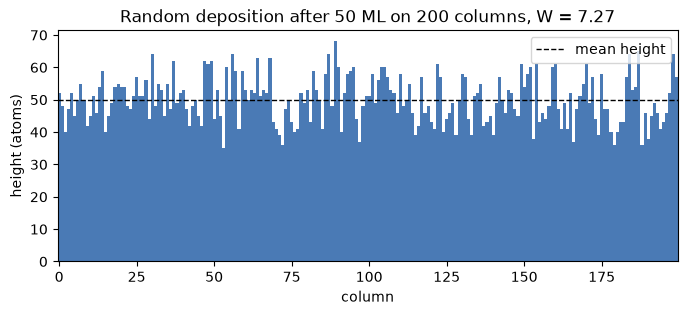

In [10]:
rng = np.random.default_rng(42)
film = np.zeros(200, dtype=np.int64)
rd.deposit(film, 200 * 50, rng)
plot_surface(film, title=f"Random deposition after 50 ML on 200 columns, W = {roughness(film):.2f}")
plt.show()

**What to notice:** the profile looks like pure noise, with no hills or valleys spanning several columns. A tall
column has no effect on its neighbours, so neighbouring heights are unrelated (**uncorrelated**).

### When do we measure? `measurement_times`

We want `W` at many times, spaced evenly on a **logarithmic** scale (1, 1.2, 1.4, ... ML up to 1000 ML) because we will
plot on log axes (Part 7). `measurement_times(n_columns, n_monolayers, n_points)` returns those times as atom counts.

In [11]:
times = measurement_times(200, 1000, 40)
print("number of times:", len(times))
print("first 8 (atoms):", times[:8], "-> monolayers:", times[:8] / 200)
print("last 3 (atoms) :", times[-3:], "-> monolayers:", times[-3:] / 200)

number of times: 40
first 8 (atoms): [200 239 285 340 406 485 579 691] -> monolayers: [1.    1.195 1.425 1.7   2.03  2.425 2.895 3.455]
last 3 (atoms) : [140341 167536 200000] -> monolayers: [ 701.705  837.68  1000.   ]


### `simulate`: one film's W(t) curve

`rd.simulate(n_columns, times, rng)` grows one film and, at each target atom count, deposits the missing atoms and
records `W`. Below is a transparent re-implementation next to the project call, with the same seed.

In [12]:
def my_simulate(n_columns, times, rng):
    heights = np.zeros(n_columns, dtype=np.int64)
    widths, deposited = [], 0
    for target in times:
        rd.deposit(heights, int(target - deposited), rng)   # top up to the target number of atoms
        deposited = target
        widths.append(roughness(heights))
    return np.array(widths)

mine = my_simulate(200, times, np.random.default_rng(1))
theirs = rd.simulate(200, times, np.random.default_rng(1))
print("identical:", np.array_equal(mine, theirs))
print("W at 1, 10, 100, 1000 ML:", np.round(theirs[[0, 13, 26, -1]], 2))

identical: True
W at 1, 10, 100, 1000 ML: [ 0.96  3.2  10.11 31.39]


**What to notice:** the two curves are identical. In this run `W` went from 0.96 at 1 ML to 3.2 at 10 ML, 10.11 at
100 ML and 31.39 at 1000 ML: each 10-fold increase in time multiplies `W` by roughly 3.16 = sqrt(10). That is
already the square-root law we will measure properly in Part 7.

### Ensemble average: `run_ensemble`

One film is noisy, like one coin toss. Theory talks about the **expected** (average) behaviour, so the project grows
`n_runs` independent films and averages them. This is called an **ensemble**. `roughness.ensemble_roughness` gives
each film its own independent random stream "spawned" from the master seed (`np.random.SeedSequence(seed).spawn(n)`),
so the whole ensemble is reproducible from one number.

It returns a table with one row per time: `roughness_mean`, and `roughness_sem`, the **standard error of the mean**
(how much the average itself would wobble if we redid the whole ensemble with new seeds; it is `std / sqrt(n_runs)`).
`run_ensemble` also adds `roughness_theory`, the exact answer (Part 8).

In [13]:
df = rd.run_ensemble(settings)        # full size: 30 films x 200,000 atoms, well under a second
df.head()

,atoms,monolayers,roughness_mean,roughness_sem,roughness_theory
0,200,1.000,0.985910,0.009554,0.997497
1,239,1.195,1.080136,0.011165,1.090424
2,285,1.425,1.174288,0.012349,1.190746
3,340,1.700,1.284410,0.013074,1.300577
4,406,2.030,1.404464,0.013871,1.421214


Is this the same table the project saved in `results/phase1_random_deposition/data.csv`? It should be, because the
seed and settings are the same.

In [14]:
saved = pd.read_csv(os.path.join(RESULTS, "phase1_random_deposition", "data.csv"))
print("rows:", len(df), "vs", len(saved))
print("max |difference| in roughness_mean:", float(np.abs(df["roughness_mean"] - saved["roughness_mean"]).max()))

rows: 40 vs 40
max |difference| in roughness_mean: 3.552713678800501e-15


**What to notice:** the difference is zero (or at floating-point noise level): rerunning reproduces the saved results
exactly, as promised in the README ("given the same library versions").

### One film vs the average

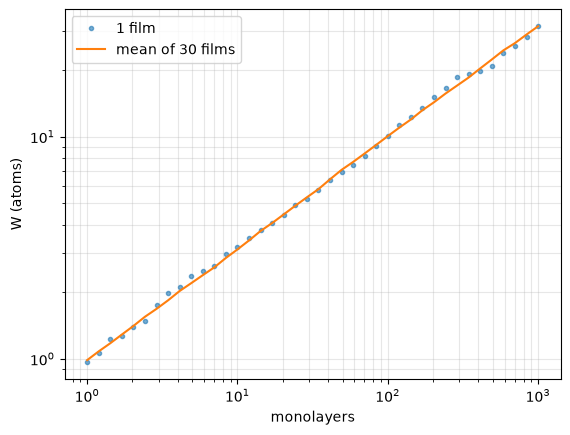

In [15]:
single = rd.simulate(200, times, np.random.default_rng(1))
plt.loglog(times / 200, single, ".", alpha=0.6, label="1 film")
plt.loglog(df["monolayers"], df["roughness_mean"], "-", label="mean of 30 films")
plt.xlabel("monolayers"); plt.ylabel("W (atoms)"); plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.show()

## 7. Power laws and log-log plots from scratch: the growth exponent beta

A **power law** is a relationship of the form $W = A\,t^{\beta}$. `beta` is called the **growth exponent**: it says how
fast roughness grows. For example `beta = 1/2` means "4 times longer gives 2 times rougher" (because $4^{1/2} = 2$).

Taking the logarithm of both sides turns it into a straight line:

$$\log W = \log A + \beta \, \log t$$

So on a **log-log plot** (both axes logarithmic, each gridline 10 times the previous) a power law is a straight line,
and its **slope is beta**. Let's see that with made-up data `W = 2 t^0.5`.

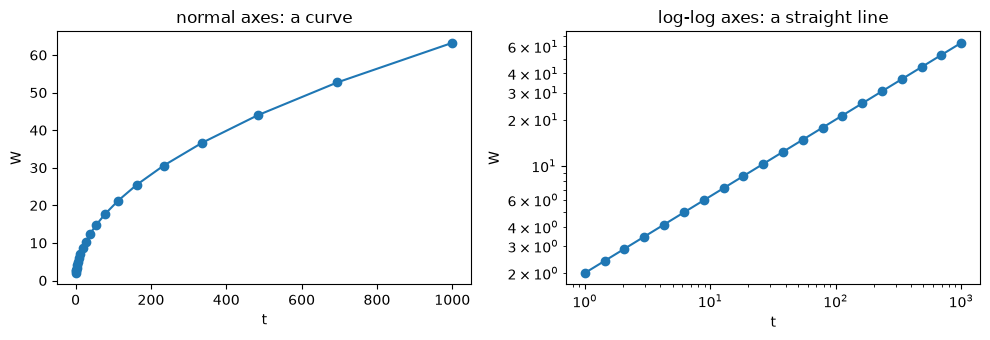

slope from two points on the log-log line: 0.500


In [16]:
t = np.logspace(0, 3, 20)          # 1 ... 1000
w = 2.0 * t ** 0.5
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(t, w, "o-"); axes[0].set(title="normal axes: a curve", xlabel="t", ylabel="W")
axes[1].loglog(t, w, "o-"); axes[1].set(title="log-log axes: a straight line", xlabel="t", ylabel="W")
plt.tight_layout(); plt.show()

slope_two_points = (np.log(w[-1]) - np.log(w[0])) / (np.log(t[-1]) - np.log(t[0]))
print(f"slope from two points on the log-log line: {slope_two_points:.3f}")

With noisy data we don't use two points; we fit the best straight line through all points in log space.
`fit_growth_exponent(times, widths)` does exactly that with SciPy's `curve_fit` on `(log t, log W)` and returns the
slope `beta` and its standard error. A least-squares straight-line fit (`np.polyfit` with degree 1) must give the same
slope; let's check on the real ensemble.

In [17]:
beta, beta_err = fit_growth_exponent(df["monolayers"], df["roughness_mean"])
slope_polyfit = np.polyfit(np.log(df["monolayers"]), np.log(df["roughness_mean"]), 1)[0]
print(f"fit_growth_exponent: beta = {beta:.4f} +/- {beta_err:.4f}")
print(f"np.polyfit slope   : {slope_polyfit:.4f}")
print("theory             : 0.5")

meta = json.load(open(os.path.join(RESULTS, "phase1_random_deposition", "settings.json")))
print("saved in results/phase1_random_deposition/settings.json:", meta["summary"])

fit_growth_exponent: beta = 0.5029 +/- 0.0005
np.polyfit slope   : 0.5029
theory             : 0.5
saved in results/phase1_random_deposition/settings.json: {'beta': 0.5028911788768851, 'beta_std_error': 0.0005071704865062587, 'beta_expected': 0.5}


**What to notice:** both fitting methods agree, and the fitted beta matches the saved value 0.5029 ± 0.0005
(`results/phase1_random_deposition/settings.json`), close to the theoretical 1/2. Fitting in log space gives early and
late times equal weight; a fit on raw `W` would be dominated by the largest, latest values.

The project's standard picture, `plot_roughness_loglog`, adds a dashed slope-1/2 reference line:

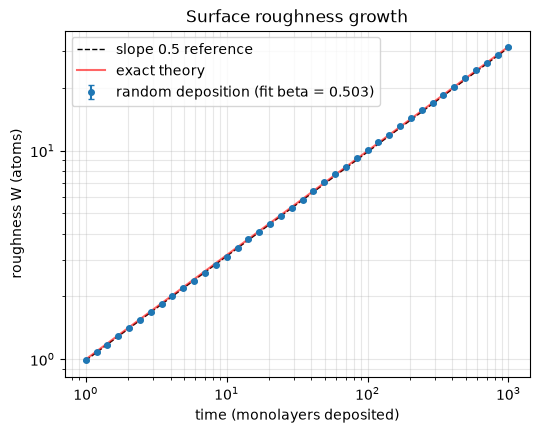

In [18]:
ax = plot_roughness_loglog({"random deposition": df}, {"random deposition": beta})
ax.plot(df["monolayers"], df["roughness_theory"], "r-", alpha=0.6, label="exact theory")
ax.legend(); plt.show()

## 8. Checking against the exact theory

Why is there an exact answer? Each atom picks a given column with probability `1/N`. After `t` atoms, the height of
one column is the number of "successes" in `t` tries with success probability `1/N`: a **binomial** random number,
`Binomial(t, 1/N)`. Its variance is `t (1/N)(1 - 1/N)`. Writing `theta = t/N` for the time in monolayers:

$$W^2 \approx \theta\,(1 - 1/N) \quad\Rightarrow\quad W = \sqrt{\theta\,(1-1/N)} \propto \theta^{1/2}$$

This is `rd.theory_roughness(monolayers, n_columns)`. Two checks:

1. the distribution of column heights should match the binomial distribution;
2. the simulated mean `W` should match the formula at every time (the test in `tests/test_random_deposition.py`
   requires within 5%).

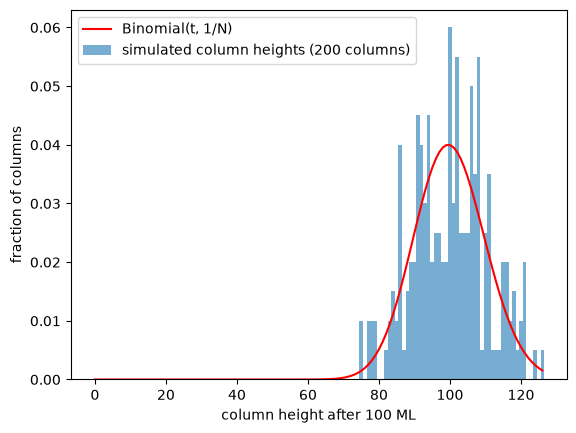

In [19]:
from scipy.stats import binom

rng = np.random.default_rng(0)
many = np.zeros(200, dtype=np.int64)
rd.deposit(many, 200 * 100, rng)            # 100 ML
counts = np.bincount(many) / len(many)
k = np.arange(len(counts))
plt.bar(k, counts, width=1.0, alpha=0.6, label="simulated column heights (200 columns)")
plt.plot(k, binom.pmf(k, 200 * 100, 1 / 200), "r-", label="Binomial(t, 1/N)")
plt.xlabel("column height after 100 ML"); plt.ylabel("fraction of columns"); plt.legend(); plt.show()

In [20]:
ratio = df["roughness_mean"] / df["roughness_theory"]
print(f"simulation / theory: min {ratio.min():.3f}, max {ratio.max():.3f}")
print("all within 5%?", bool(np.all(np.abs(ratio - 1) < 0.05)))

simulation / theory: min 0.976, max 1.012
all within 5%? True


**What to notice:** the histogram follows the binomial curve and the ratio stays within a few percent of 1 at every
time. The `rd.theory_roughness` docstring adds a subtlety: the formula is the root-mean-square width, and the average
of `W` is a hair below it, which is negligible for `N = 200`.

The same checks are automated as tests in `tests/test_random_deposition.py` (flat surface has `W = 0`,
`deposit_one` adds exactly one atom, beta = 0.5 within 0.03, theory within 5%, same seed reproduces, and the fitter
recovers a known exponent). You can run them with `.venv/bin/python -m pytest -q tests/test_random_deposition.py`.

## 9. Small experiments: what changes and what doesn't

**Does substrate width matter?** The theory says `W ≈ sqrt(theta)` for any reasonably large `N`. And roughness
**never saturates** (never levels off), because columns never talk to each other.

In [21]:
for n in (50, 200, 800):
    d = rd.run_ensemble(rd.RDSettings(n_columns=n, n_monolayers=1000, n_runs=10, seed=1))
    b, _ = fit_growth_exponent(d["monolayers"], d["roughness_mean"])
    print(f"N = {n:4d}: W at 1000 ML = {d['roughness_mean'].iloc[-1]:6.2f} (theory {d['roughness_theory'].iloc[-1]:.2f}), beta = {b:.3f}")

N =   50: W at 1000 ML =  31.61 (theory 31.30), beta = 0.498
N =  200: W at 1000 ML =  31.09 (theory 31.54), beta = 0.498
N =  800: W at 1000 ML =  31.89 (theory 31.60), beta = 0.499


**What to notice:** at 1000 ML all three widths give `W` between about 31 and 32 and `beta` of about 0.50: a 16 times
wider substrate does not change the roughness. Compare this with notebook 2, where width matters a lot.

**How many films do we need?** More runs make the average smoother: the standard error shrinks like
`1/sqrt(n_runs)`.

In [22]:
for runs in (3, 30):
    d = rd.run_ensemble(rd.RDSettings(n_runs=runs, seed=5))
    b, b_err = fit_growth_exponent(d["monolayers"], d["roughness_mean"])
    print(f"n_runs = {runs:2d}: mean standard error of W = {d['roughness_sem'].mean():.3f}, beta = {b:.4f} +/- {b_err:.4f}")

n_runs =  3: mean standard error of W = 0.206, beta = 0.4915 +/- 0.0012
n_runs = 30: mean standard error of W = 0.079, beta = 0.4993 +/- 0.0007


**What to notice:** with 3 films the fitted `beta` (0.4915) is off from 1/2 by much more than its quoted error
(0.0012). The fit's error bar assumes every point is independent, but the `W` values at successive times come from
the *same* growing films, so their errors are correlated. Treat the `+/-` from `fit_growth_exponent` as a lower
bound, and trust exponents more when they come from many runs (the project uses 30).

## 10. How `results/phase1_random_deposition/` is produced

The notebook never writes files. The saved results come from `scripts/run_phase1.py`, run from the project root with
`PYTHONPATH=src .venv/bin/python scripts/run_phase1.py`. It does exactly what Parts 6 and 7 did:

1. `settings = rd.RDSettings()` (the defaults);
2. `df = rd.run_ensemble(settings)`;
3. `beta, beta_err = fit_growth_exponent(...)`;
4. `plot_roughness_loglog(...)` plus the red exact-theory line;
5. `results.save_result("phase1_random_deposition", settings.to_dict(), df, summary=..., figure=...)`, which writes
   `settings.json` (inputs, seed, summary numbers, library versions, timestamp), `data.csv` (the table) and
   `figure.png`.

Here is what was saved (read only):

In [23]:
print(json.dumps(meta, indent=2))

{
  "settings": {
    "model": "random_deposition",
    "n_columns": 200,
    "n_monolayers": 1000,
    "n_runs": 30,
    "n_points": 40,
    "seed": 42
  },
  "summary": {
    "beta": 0.5028911788768851,
    "beta_std_error": 0.0005071704865062587,
    "beta_expected": 0.5
  },
  "created_utc": "2026-10-11T11:09:38+00:00",
  "python": "3.12.8",
  "numpy": "2.5.3",
  "pandas": "3.0.6"
}


## 11. Recap and exercises

### What we learned
* A 1D film is an array of column heights; random deposition adds 1 to a random column.
* Roughness `W` is the standard deviation of the heights.
* `W` grows as a power law `t^beta`; on a log-log plot the slope is `beta`. Random deposition gives `beta = 1/2`
  (saved fit 0.5029) and never saturates.
* The simulation matches an exact theory, which validates the deposition loop, the roughness measurement and the
  fitting code before any physics is added.

### Step → module/function → script map

| Step | Module / function | Script / test |
|---|---|---|
| drop one atom | `random_deposition.deposit_one` | `tests/test_random_deposition.py` |
| drop many atoms fast | `random_deposition.deposit` (np.bincount) | |
| measure W | `roughness.roughness` | |
| log-spaced times | `roughness.measurement_times` | |
| one film's W(t) | `random_deposition.simulate` | |
| average many films | `roughness.ensemble_roughness` via `random_deposition.run_ensemble` | `scripts/run_phase1.py` |
| fit beta | `roughness.fit_growth_exponent` | `scripts/run_phase1.py` |
| exact theory | `random_deposition.theory_roughness` | `tests/test_random_deposition.py` |
| save results | `results.save_result` | `scripts/run_phase1.py` → `results/phase1_random_deposition/` |
| plots | `plotting.plot_surface`, `plotting.plot_roughness_loglog` | |

### Try changing X and see Y
1. In Part 4, change `SEED`. The film changes, but all three methods still agree.
2. In Part 4, grow 500 ML instead of 5 and print `roughness(heights) / np.sqrt(500)`. It should be close to 1.
3. In Part 7, fit only the first 10 points (`df.iloc[:10]`). How much does `beta` change, and why is its error larger?
4. Replace `W` by the *mean absolute deviation* `np.mean(np.abs(h - h.mean()))`. Is the exponent still about 1/2?
5. Change `n_runs` to 1 in `RDSettings` and fit `beta`. How noisy is a single film's exponent?

**Next:** notebook 2 lets atoms roll into lower neighbouring columns, and roughness behaves completely differently.